In [2]:
#!pip install gower  
#!pip install kmodes 
#!pip install stepmix
import numpy as np
import pandas as pd
import gower
import matplotlib.pyplot as plt
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from stepmix.stepmix import StepMix
from stepmix.utils import get_mixed_descriptor

import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import kruskal


In [3]:
df = pd.read_parquet("clean_steam_games.parquet")

In [4]:
df.columns

Index(['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu',
       'required_age', 'price', 'detailed_description', 'short_description',
       'supported_languages', 'full_audio_languages', 'reviews', 'windows',
       'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score',
       'positive', 'negative', 'score_rank', 'achievements', 'recommendations',
       'developers', 'publishers', 'categories', 'genres', 'tags',
       'release_year', 'release_month', 'age', 'has_metacritic_score',
       'owner_group', 'pub_prior_games_max', 'pub_prior_games_mean',
       'pub_all_first_release', 'pub_any_first_release', 'dev_prior_games_max',
       'dev_prior_games_mean', 'dev_all_first_release',
       'dev_any_first_release', 'lang_english', 'lang_chinese',
       'lang_japanese', 'lang_spanish', 'lang_german', 'lang_french',
       'lang_russian', 'lang_portuguese', 'lang_italian', 'lang_korean',
       'other_langs', 'total_langs', 'num_platforms', 'genre_action',


In [10]:
df.shape

(119036, 82)

In [11]:
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

def parse_list(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        return list(x)
    if pd.isna(x):
        return []
    try:
        return ast.literal_eval(x)
    except (ValueError, SyntaxError):
        return [p.strip() for p in str(x).split(',') if p.strip()]

df['publishers_list'] = df['publishers'].apply(parse_list)

# one row per (appID, publisher)
exploded = df[['appID', 'release_date', 'publishers_list']].explode('publishers_list')
exploded = exploded.rename(columns={'publishers_list': 'publisher'}).dropna(subset=['publisher', 'release_date'])

# each publisher's first release date anywhere in the dataset
first_release = exploded.groupby('publisher')['release_date'].min().rename('pub_first_release_date')
exploded = exploded.merge(first_release, on='publisher', how='left')

exploded['years_active_this_pub'] = (
    (exploded['release_date'] - exploded['pub_first_release_date']).dt.days / 365.25
)

# collapse back to one row per game — use max to mirror pub_prior_games_max,
# or .mean() if you want it to mirror pub_prior_games_mean
pub_years = exploded.groupby('appID')['years_active_this_pub'].max().rename('publisher_years_active')

df = df.merge(pub_years, on='appID', how='left')

In [12]:
df['developers_list'] = df['developers'].apply(parse_list)

# one row per (appID, developer)
exploded_dev = df[['appID', 'release_date', 'developers_list']].explode('developers_list')
exploded_dev = exploded_dev.rename(columns={'developers_list': 'developer'}).dropna(subset=['developer', 'release_date'])

# each developer's first release date anywhere in the dataset
first_release_dev = exploded_dev.groupby('developer')['release_date'].min().rename('dev_first_release_date')
exploded_dev = exploded_dev.merge(first_release_dev, on='developer', how='left')

exploded_dev['years_active_this_dev'] = (
    (exploded_dev['release_date'] - exploded_dev['dev_first_release_date']).dt.days / 365.25
)

# collapse back to one row per game — max to mirror dev_prior_games_max
dev_years = exploded_dev.groupby('appID')['years_active_this_dev'].max().rename('dev_years_active')

df = df.merge(dev_years, on='appID', how='left')

In [13]:
df.columns

Index(['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu',
       'required_age', 'price', 'detailed_description', 'short_description',
       'supported_languages', 'full_audio_languages', 'reviews', 'windows',
       'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score',
       'positive', 'negative', 'score_rank', 'achievements', 'recommendations',
       'developers', 'publishers', 'categories', 'genres', 'tags',
       'release_year', 'release_month', 'age', 'has_metacritic_score',
       'owner_group', 'pub_prior_games_max', 'pub_prior_games_mean',
       'pub_all_first_release', 'pub_any_first_release', 'dev_prior_games_max',
       'dev_prior_games_mean', 'dev_all_first_release',
       'dev_any_first_release', 'lang_english', 'lang_chinese',
       'lang_japanese', 'lang_spanish', 'lang_german', 'lang_french',
       'lang_russian', 'lang_portuguese', 'lang_italian', 'lang_korean',
       'other_langs', 'total_langs', 'num_platforms', 'genre_action',


In [14]:
df.sample(20, random_state=42)[['categories', 'genres']].head(25)

,categories,genres
42130,[],[Free To Play]
38242,"[Single-player, Steam Achievements, Steam Trad...","[Action, Indie]"
64063,"[Single-player, Multi-player, PvP, Online PvP,...","[Action, Adventure, Casual, Indie, RPG, Simula..."
26621,"[Single-player, Steam Achievements, Full contr...","[Adventure, Indie]"
102253,"[Single-player, Steam Achievements, Steam Clou...",[Casual]
18875,"[Single-player, Steam Achievements, Full contr...","[Action, Indie]"
2783,"[Single-player, Steam Achievements, Full contr...","[Action, Indie]"
12524,"[Single-player, Steam Achievements, Partial Co...","[Action, Casual, Indie, Simulation]"
88140,"[Single-player, Family Sharing]","[Indie, RPG]"
62686,"[Single-player, Family Sharing]","[Adventure, Indie, Simulation, Early Access]"


In [15]:
df['categories_list'] = df['categories'].apply(parse_list)
df['genres_list'] = df['genres'].apply(parse_list)

df['total_cat'] = df['categories_list'].apply(len)
df['total_genres'] = df['genres_list'].apply(len)

In [16]:
model_df=df.copy()
model_df['publisher_years_active'] = model_df['publisher_years_active'].fillna(0)
model_df['dev_years_active'] = model_df['dev_years_active'].fillna(0)

In [17]:
model_df[['pub_prior_games_max', 'publisher_years_active', 'total_langs', 'total_cat', 'total_genres', 'dev_prior_games_max', 'dev_years_active']].describe()

,pub_prior_games_max,publisher_years_active,total_langs,total_cat,total_genres,dev_prior_games_max,dev_years_active
count,119036.000000,119036.000000,119036.000000,119036.000000,119036.000000,119036.000000,119036.000000
mean,8.942244,1.315662,4.970572,4.136051,2.701712,3.499698,1.005570
std,31.082518,2.298498,13.065551,3.091647,1.500025,12.856867,1.965289
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,2.000000,2.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000,3.000000,3.000000,0.000000,0.000000
75%,3.000000,1.765914,4.000000,5.000000,4.000000,1.000000,1.092402
max,553.000000,10.904860,99.000000,32.000000,19.000000,230.000000,10.934976


In [18]:
df[['pub_prior_games_max', 'publisher_years_active', 'total_langs',
    'total_cat', 'total_genres', 'dev_prior_games_max', 'dev_years_active']].skew()

pub_prior_games_max       7.912840
publisher_years_active    1.836638
total_langs               6.182003
total_cat                 1.507901
total_genres              0.487535
dev_prior_games_max       7.426944
dev_years_active          2.217157
dtype: float64

In [19]:

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)


NUMERIC_COLS = [
    'pub_prior_games_max', 'publisher_years_active', 'total_langs', 'total_cat', 'total_genres', 'dev_prior_games_max', 'dev_years_active'
]
SKEWED_COLS = ['pub_prior_games_max', 'publisher_years_active', 'total_langs', 'total_cat', 'dev_prior_games_max','dev_years_active']

CATEGORICAL_COLS = [
    'genre_action', 'genre_adventure', 'genre_casual', 'genre_early_access',
    'genre_free_to_play', 'genre_indie', 'genre_massively_multiplayer',
    'genre_racing', 'genre_rpg', 'genre_simulation', 'genre_sports',
    'genre_strategy', 'genre_violent', 'genre_gore',
    'cat_single_player', 'cat_multiplayer', 'cat_coop', 'cat_online',
    'cat_local_multiplayer', 'cat_mmo', 'cat_controller_support', 'cat_vr',
    'cat_achievements', 'cat_trading_cards', 'cat_leaderboards',
    'cat_workshop', 'cat_in_app_purchases', 'lang_english',
    'lang_chinese', 'lang_japanese', 'lang_spanish', 'lang_german',
    'lang_french', 'lang_russian', 'lang_portuguese', 'lang_italian',
    'lang_korean', 'other_langs' ,
    'windows', 'mac', 'linux',
]


In [20]:
for col in SKEWED_COLS:
    model_df[col] = np.log1p(model_df[col])

scaler = StandardScaler()
model_df[NUMERIC_COLS] = scaler.fit_transform(model_df[NUMERIC_COLS])

In [21]:
model_df[['pub_prior_games_max', 'publisher_years_active', 'total_langs', 'total_cat', 'total_genres', 'dev_prior_games_max', 'dev_years_active']].describe()

,pub_prior_games_max,publisher_years_active,total_langs,total_cat,total_genres,dev_prior_games_max,dev_years_active
count,1.190360e+05,1.190360e+05,1.190360e+05,1.190360e+05,1.190360e+05,1.190360e+05,1.190360e+05
mean,8.977589e-17,1.528100e-17,-2.788783e-16,1.680910e-16,3.438226e-17,6.589932e-17,6.876451e-17
std,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00
min,-6.574892e-01,-6.949212e-01,-1.355781e+00,-2.358683e+00,-1.801119e+00,-6.033698e-01,-6.211929e-01
25%,-6.574892e-01,-6.949212e-01,-5.610342e-01,-5.842812e-01,-4.678022e-01,-6.033698e-01,-6.211929e-01
50%,-6.574892e-01,-6.949212e-01,-5.610342e-01,-1.196372e-01,1.988561e-01,-6.033698e-01,-6.211929e-01
75%,3.801079e-01,6.920668e-01,4.895645e-01,5.352417e-01,8.655145e-01,9.087674e-02,4.933648e-01
max,4.070707e+00,2.681915e+00,3.924405e+00,3.288632e+00,1.086539e+01,4.847680e+00,3.121821e+00


In [22]:
### create a list or a mask to specify which variabes are categorical and which are numeric for the KPrototypes model
X = model_df[NUMERIC_COLS + CATEGORICAL_COLS].values
cat_idx = list(range(len(NUMERIC_COLS), len(NUMERIC_COLS) + len(CATEGORICAL_COLS)))
cat_mask = np.array([False] * len(NUMERIC_COLS) + [True] * len(CATEGORICAL_COLS))  # for gower

assert model_df[NUMERIC_COLS + CATEGORICAL_COLS].isna().sum().sum() == 0, "NaNs present — resolve before fitting"

In [19]:
# find a good gammar value to being with to assume that the contribution between numeric and categorical features is balanced. 
# #This is done by sampling pairs of rows and computing the average numeric distance and the average categorical mismatch, then taking the ratio of the two.
N = len(model_df)
n_pairs = 1000
rng = np.random.default_rng(RANDOM_STATE)

i_idx = rng.integers(0, N, size=n_pairs)
j_idx = rng.integers(0, N, size=n_pairs)
keep = i_idx != j_idx
i_idx, j_idx = i_idx[keep], j_idx[keep]

num_arr = model_df[NUMERIC_COLS].values
cat_arr = model_df[CATEGORICAL_COLS].values

num_dists = ((num_arr[i_idx] - num_arr[j_idx]) ** 2).sum(axis=1)
cat_dists = (cat_arr[i_idx] != cat_arr[j_idx]).sum(axis=1)

gamma_balanced = num_dists.mean() / cat_dists.mean()
print(f"typical numeric distance = {num_dists.mean():.2f}")
print(f"typical categorical mismatch = {cat_dists.mean():.2f}")
print(f"gamma_balanced = {gamma_balanced:.3f}")

typical numeric distance = 13.18
typical categorical mismatch = 9.50
gamma_balanced = 1.387


In [39]:
## to find a good value for gower distance,  sample a subset of the data and compute the Gower distance matrix. 
# This will give us an idea of the typical distances between observations in our dataset, which can help inform our choice of gamma for the KPrototypes model.
SAMPLE_N = 10000
sample_idx = rng.choice(len(model_df), size=min(SAMPLE_N, len(model_df)), replace=False)

D_gower = gower.gower_matrix(
    model_df[NUMERIC_COLS + CATEGORICAL_COLS].iloc[sample_idx],
    cat_features=cat_mask,
)

In [40]:
gamma_balanced = 1.387
gamma_multipliers = [0.5, 1.0, 2.0, 4.0, 6.0, 8.0, 10.0]
k_range = range(2, 6)

results = []
labels_store = {}

X = model_df[NUMERIC_COLS + CATEGORICAL_COLS].values
cat_idx = cat_idx

for mult in gamma_multipliers:
    gamma = mult * gamma_balanced
    for k in k_range:
        kp = KPrototypes(n_clusters=k, init='Cao', n_init=5, gamma=gamma,
                          random_state=RANDOM_STATE, verbose=0)
        labels = kp.fit_predict(X, categorical=cat_idx)
        sil = silhouette_score(D_gower, labels[sample_idx], metric='precomputed')

        results.append({'gamma_mult': mult, 'gamma': gamma, 'k': k,
                         'cost': kp.cost_, 'silhouette_gower': sil})
        labels_store[(mult, k)] = labels
        print(f"gamma={gamma:.2f} (={mult}x) | k={k} | cost={kp.cost_:,.1f} | silhouette={sil:.3f}")

results_df = pd.DataFrame(results)

gamma=0.69 (=0.5x) | k=2 | cost=1,056,327.3 | silhouette=0.162
gamma=0.69 (=0.5x) | k=3 | cost=923,200.7 | silhouette=0.190
gamma=0.69 (=0.5x) | k=4 | cost=842,283.6 | silhouette=0.074
gamma=0.69 (=0.5x) | k=5 | cost=786,552.2 | silhouette=0.079
gamma=1.39 (=1.0x) | k=2 | cost=1,565,519.2 | silhouette=0.418
gamma=1.39 (=1.0x) | k=3 | cost=1,354,837.0 | silhouette=0.177
gamma=1.39 (=1.0x) | k=4 | cost=1,270,745.8 | silhouette=0.143
gamma=1.39 (=1.0x) | k=5 | cost=1,201,600.9 | silhouette=0.101
gamma=2.77 (=2.0x) | k=2 | cost=2,423,616.6 | silhouette=0.436
gamma=2.77 (=2.0x) | k=3 | cost=2,337,992.5 | silhouette=0.369
gamma=2.77 (=2.0x) | k=4 | cost=2,289,249.7 | silhouette=0.350
gamma=2.77 (=2.0x) | k=5 | cost=2,103,973.3 | silhouette=0.137
gamma=5.55 (=4.0x) | k=2 | cost=4,130,050.7 | silhouette=0.438
gamma=5.55 (=4.0x) | k=3 | cost=4,000,617.6 | silhouette=0.386
gamma=5.55 (=4.0x) | k=4 | cost=3,942,361.0 | silhouette=0.365
gamma=5.55 (=4.0x) | k=5 | cost=3,750,570.9 | silhouette=0.15

In [22]:
# check the stability of the clustering results across different gamma values for a fixed k by computing the Adjusted Rand Index (ARI) between the cluster labels obtained with different gamma values. A higher ARI indicates more similar clustering results, suggesting that the clustering is stable with respect to changes in gamma.
def gamma_stability_matrix(k_candidate, gamma_multipliers, labels_store):
    n = len(gamma_multipliers)
    mat = np.eye(n)
    for a in range(n):
        for b in range(a + 1, n):
            ari = adjusted_rand_score(labels_store[(gamma_multipliers[a], k_candidate)],
                                       labels_store[(gamma_multipliers[b], k_candidate)])
            mat[a, b] = mat[b, a] = ari
    return pd.DataFrame(mat, index=[f'{g}x' for g in gamma_multipliers],
                              columns=[f'{g}x' for g in gamma_multipliers])

for k in k_range:
    print(f"\nk={k} ARI stability matrix:")
    print(gamma_stability_matrix(k, gamma_multipliers, labels_store).round(3))


k=2 ARI stability matrix:
        0.5x   1.0x   2.0x   4.0x   6.0x   8.0x  10.0x
0.5x   1.000  0.199  0.149  0.134  0.127  0.126  0.126
1.0x   0.199  1.000  0.892  0.858  0.845  0.842  0.842
2.0x   0.149  0.892  1.000  0.964  0.951  0.947  0.947
4.0x   0.134  0.858  0.964  1.000  0.986  0.983  0.983
6.0x   0.127  0.845  0.951  0.986  1.000  0.997  0.996
8.0x   0.126  0.842  0.947  0.983  0.997  1.000  1.000
10.0x  0.126  0.842  0.947  0.983  0.996  1.000  1.000

k=3 ARI stability matrix:
        0.5x   1.0x   2.0x   4.0x   6.0x   8.0x  10.0x
0.5x   1.000  0.895  0.496  0.460  0.457  0.465  0.461
1.0x   0.895  1.000  0.492  0.466  0.463  0.474  0.474
2.0x   0.496  0.492  1.000  0.858  0.855  0.860  0.839
4.0x   0.460  0.466  0.858  1.000  0.992  0.919  0.896
6.0x   0.457  0.463  0.855  0.992  1.000  0.919  0.897
8.0x   0.465  0.474  0.860  0.919  0.919  1.000  0.910
10.0x  0.461  0.474  0.839  0.896  0.897  0.910  1.000

k=4 ARI stability matrix:
        0.5x   1.0x   2.0x   4.0x   6.0

In [ ]:
# --- shared chart system (from the dataviz reference palette) ---
K_COLORS = {2: '#2a475e', 3: '#ab2838', 4: '#66c0f4', 5: '#c7d50e'}  # slots 1-4, fixed order
INK_PRIMARY = '#0b0b0b'
INK_SECONDARY = '#52514e'
INK_MUTED = '#898781'
GRIDLINE = '#e1e0d9'
SURFACE = '#fcfcfb'

BLUE_SEQ = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7',
            '#3987e5', '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']
blue_seq_cmap = LinearSegmentedColormap.from_list('blue_seq', BLUE_SEQ)

def _style_axes(ax):
    ax.set_facecolor(SURFACE)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color(GRIDLINE)
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    #ax.grid(axis='y', color=GRIDLINE, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

In [31]:
def plot_silhouette_vs_gamma(results_df, k_colors=K_COLORS):
    fig, ax = plt.subplots(figsize=(8, 5))
    for k, color in k_colors.items():
        sub = results_df[results_df['k'] == k].sort_values('gamma_mult')
        ax.plot(sub['gamma_mult'], sub['silhouette_gower'], color=color,
                linewidth=2, marker='o', markersize=8, label=f'k={k}', zorder=3)
        # direct end-label
        last = sub.iloc[-1]
        ax.annotate(f'k={k}', (last['gamma_mult'], last['silhouette_gower']),
                     xytext=(6, 0), textcoords='offset points',
                     color=color, fontsize=9, va='center', fontweight='bold')
    ax.set_xlabel('gamma multiplier', color=INK_SECONDARY)
    ax.set_ylabel('silhouette (Gower)', color=INK_SECONDARY)
    ax.set_title('Silhouette vs. gamma, by k', color=INK_PRIMARY, fontsize=12, loc='left')
    _style_axes(ax)
    ax.legend(frameon=False, labelcolor=INK_SECONDARY, loc='lower right')

    return plt.tight_layout()

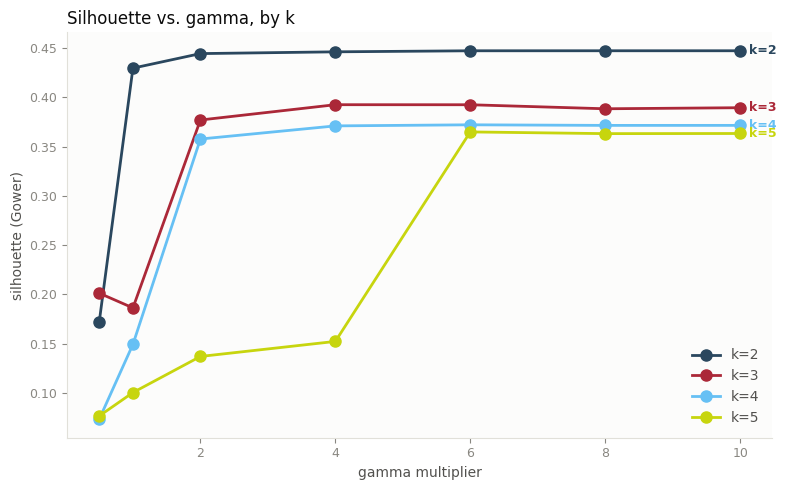

In [32]:
plot_silhouette_vs_gamma(results_df)

In [33]:
def plot_ari_heatmaps(ari_matrices, gamma_multipliers):
    """ari_matrices: dict {k: pd.DataFrame} — the 7x7 ARI tables you already built per k."""
    ks = sorted(ari_matrices.keys())
    fig, axes = plt.subplots(1, len(ks), figsize=(4.2 * len(ks), 4.2))
    labels = [f'{g}x' for g in gamma_multipliers]

    for ax, k in zip(axes, ks):
        mat = ari_matrices[k].values
        im = ax.imshow(mat, cmap=blue_seq_cmap, vmin=0, vmax=1, aspect='auto')
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
        ax.set_title(f'k={k}', color=INK_PRIMARY, fontsize=11, loc='left')
        ax.tick_params(colors=INK_MUTED)
        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.colorbar(im, ax=axes, shrink=0.8, label='ARI', pad=0.02)
    fig.suptitle('Cluster-assignment stability across gamma, by k', color=INK_PRIMARY, fontsize=12, x=0.12, ha='left')
    return  fig.suptitle('Cluster-assignment stability across gamma, by k', color=INK_PRIMARY, fontsize=12, x=0.12, ha='left')

Text(0.12, 0.98, 'Cluster-assignment stability across gamma, by k')

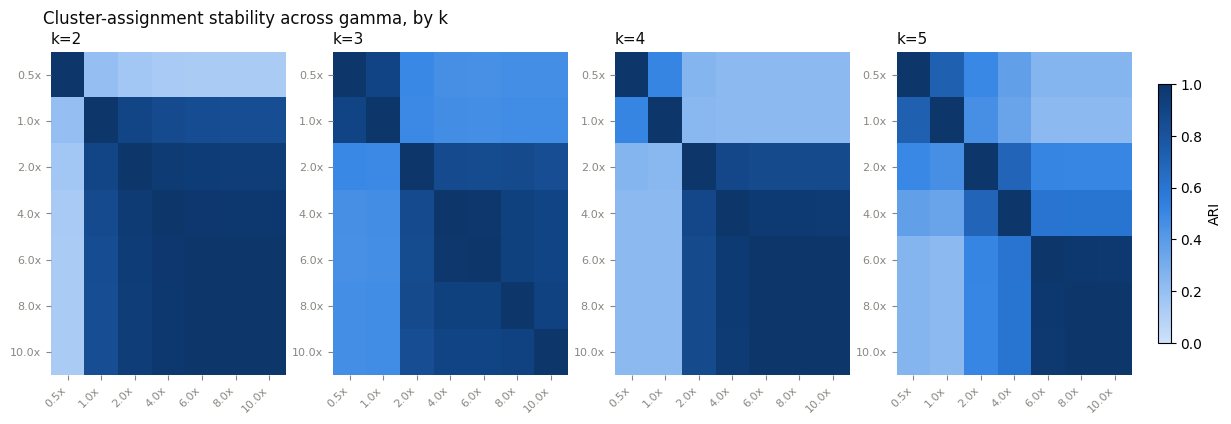

In [34]:
plot_ari_heatmaps({k: gamma_stability_matrix(k, gamma_multipliers, labels_store) for k in k_range}, gamma_multipliers)  

In [31]:
K_CHOSEN = 2          # set after reading results_df / the stability check
GAMMA_MULT_CHOSEN = 6  # set after the stability check

final_gamma = GAMMA_MULT_CHOSEN * gamma_balanced
kp_final = KPrototypes(n_clusters=K_CHOSEN, init='Cao', n_init=10, gamma=final_gamma,
                        random_state=RANDOM_STATE, verbose=1)
model_df['cluster'] = kp_final.fit_predict(X, categorical=cat_idx)

Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 1, iteration: 1/100, moves: 15167, ncost: 5835065.711876094
Run: 1, iteration: 2/100, moves: 1252, ncost: 5835001.756668622
Run: 1, iteration: 3/100, moves: 4, ncost: 5835001.745194
Run: 1, iteration: 4/100, moves: 0, ncost: 5835001.745194
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 2, iteration: 1/100, moves: 14154, ncost: 5835053.629036128
Run: 2, iteration: 2/100, moves: 1176, ncost: 5835001.756668625
Run: 2, iteration: 3/100, moves: 4, ncost: 5835001.745194005
Run: 2, iteration: 4/100, moves: 0, ncost: 5835001.745194005
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 3, iteration: 1/100, moves: 12863, ncost: 5835045.798744229
Run: 3, iteration: 2/100, moves: 814, ncost: 5835001.747376195
Run: 3, iteration: 3/100, moves: 2, ncost: 5835001.745194008

In [32]:
group_order = ['Low (<20K owners)', 'Mid (20K-100K owners)', 'High (100K+ owners)']
owner_group_rank_map = {grp: i for i, grp in enumerate(group_order)}
model_df[['owner_group', 'cluster']].groupby('cluster')['owner_group'].value_counts(normalize=True).unstack().fillna(0).round(3) [group_order]

owner_group,Low (<20K owners),Mid (20K-100K owners),High (100K+ owners)
cluster,,,
0,0.840,0.124,0.036
1,0.687,0.159,0.153


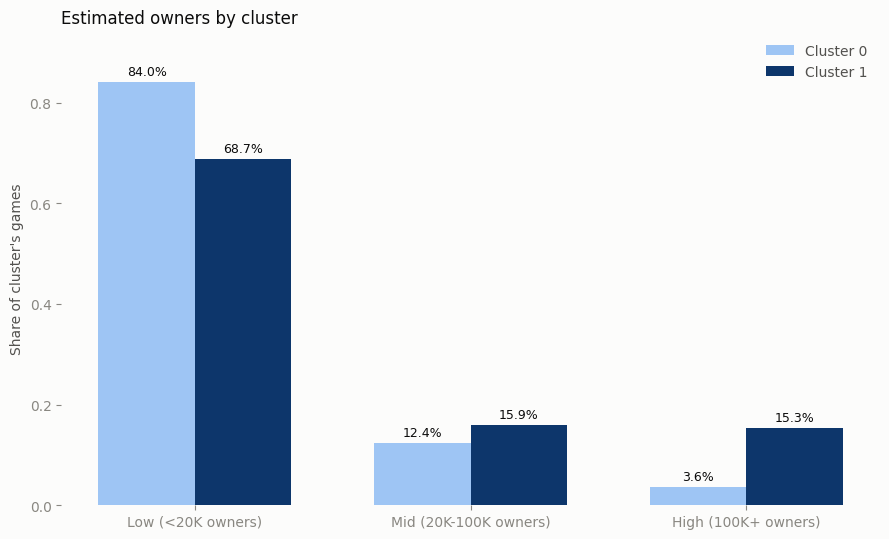

In [46]:
ct = pd.crosstab(model_df['cluster'], model_df['owner_group'], normalize='index')
ct = ct[group_order]

CLUSTER_COLORS = {0: '#9ec5f4', 1: '#0d366b'}

fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

x = np.arange(len(group_order))
bar_w = 0.35
for i, c in enumerate(ct.index):
    bars = ax.bar(x + (i - 0.5) * bar_w, ct.loc[c].values, width=bar_w,
                   color=CLUSTER_COLORS[c], label=f'Cluster {c}')
    ax.bar_label(bars, labels=[f'{v:.1%}' for v in ct.loc[c].values],
                 padding=3, fontsize=9, color=INK_PRIMARY)

ax.set_xticks(x)
ax.set_xticklabels(group_order, color=INK_PRIMARY)
ax.set_ylabel("Share of cluster's games", color=INK_SECONDARY)
ax.set_title('Estimated owners by cluster', color=INK_PRIMARY, fontsize=12, loc='left')
ax.tick_params(colors=INK_MUTED)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(frameon=False, labelcolor=INK_SECONDARY)
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

In [ ]:
# Use the 3-group ordinal variable instead of the full 14-tier one

owner_group_rank_map = {grp: i for i, grp in enumerate(group_order)}
model_df['owner_group_rank'] = model_df['owner_group'].map(owner_group_rank_map)

groups = [model_df.loc[model_df['cluster'] == c, 'owner_group_rank'].dropna().values
          for c in sorted(model_df['cluster'].unique())]

H_stat, p_value = kruskal(*groups)

n = sum(len(g) for g in groups)
epsilon_sq = H_stat / (n - 1)

def interpret_epsilon2(e2):
    if e2 < 0.01:   return "negligible"
    elif e2 < 0.04: return "weak"
    elif e2 < 0.16: return "moderate"
    elif e2 < 0.36: return "relatively strong"
    elif e2 < 0.64: return "strong"
    else:           return "very strong"

print(f"Kruskal-Wallis H = {H_stat:.2f}, p = {p_value:.4g}")
print(f"epsilon-squared = {epsilon_sq:.4f} ({interpret_epsilon2(epsilon_sq)})")

Kruskal-Wallis H = 3415.72, p = 0
epsilon-squared = 0.0287 (weak)


In [50]:

mixed_data, mixed_descriptor = get_mixed_descriptor(
    dataframe=model_df[NUMERIC_COLS + CATEGORICAL_COLS],
    continuous=NUMERIC_COLS,
    binary=CATEGORICAL_COLS,
)


MIN_CLASS_SHARE = 0.05  # smallest acceptable class, as a fraction of all games — adjust as needed


results = []
models = {}

for k in range(2, 11):
    lca = StepMix(
        n_components=k,
        measurement=mixed_descriptor,
        n_init=10,
        init_params='random',
        random_state=RANDOM_STATE,
        verbose=0,
    )
    lca.fit(mixed_data)

    labels = lca.predict(mixed_data)
    class_shares = pd.Series(labels).value_counts(normalize=True)
    min_share = class_shares.min()

    results.append({
        'k': k,
        'bic': lca.bic(mixed_data),
        'caic': lca.caic(mixed_data),
        'entropy': lca.relative_entropy(mixed_data),
        'min_class_share': min_share,
        'meets_size_floor': min_share >= MIN_CLASS_SHARE,
    })
    models[k] = lca

results_df = pd.DataFrame(results)
print(results_df)

Fitting StepMix...


Initializations (n_init) : 100%|██████████| 10/10 [00:02<00:00,  3.62it/s, max_LL=5.23e+6, max_avg_LL=44]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 10/10 [00:05<00:00,  1.73it/s, max_LL=6.96e+6, max_avg_LL=58.5]


Fitting StepMix...


...

Fitting StepMix...


Initializations (n_init) : 100%|██████████| 10/10 [00:40<00:00,  4.05s/it, max_LL=7.46e+6, max_avg_LL=62.7]


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 10/10 [00:51<00:00,  5.13s/it, max_LL=7.67e+6, max_avg_LL=64.4]

    k           bic          caic   entropy  min_class_share  meets_size_floor
0   2 -1.046437e+07 -1.046426e+07  0.995848         0.147569              True
1   3 -1.391952e+07 -1.391935e+07  0.997271         0.130759              True
2   4 -1.429945e+07 -1.429922e+07  0.996481         0.126878              True
3   5 -1.461862e+07 -1.461834e+07  0.996968         0.053555              True
4   6 -1.468473e+07 -1.468440e+07  0.992451         0.053555              True
5   7 -1.510514e+07 -1.510475e+07  0.992544         0.038829             False
6   8 -1.516966e+07 -1.516922e+07  0.993614         0.019263             False
7   9 -1.491265e+07 -1.491215e+07  0.977003         0.018146             False
8  10 -1.533134e+07 -1.533078e+07  0.987333         0.019305             False


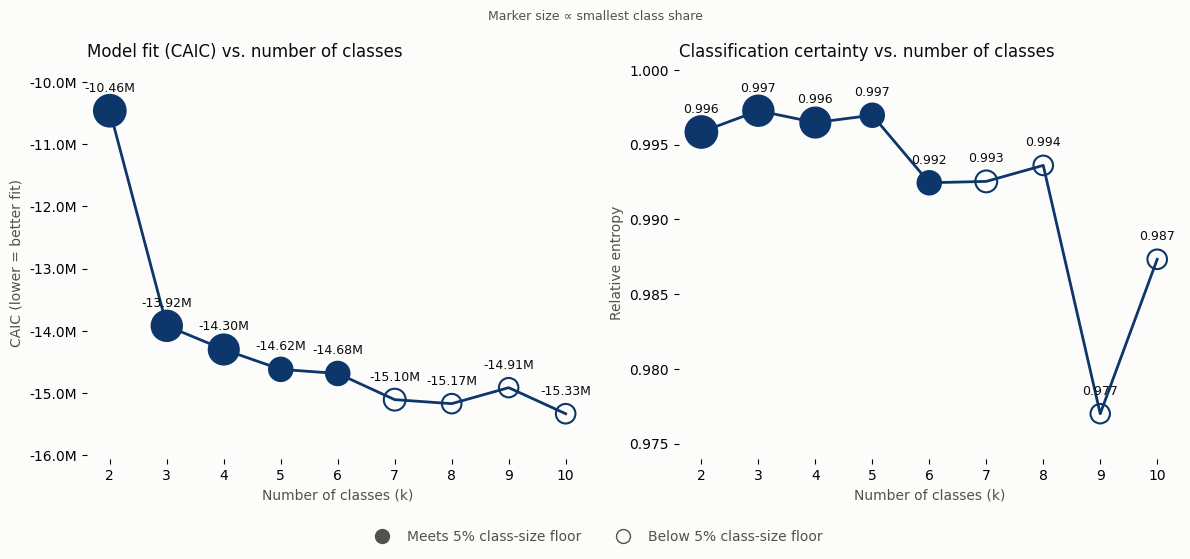

In [54]:


k_vals = results_df['k'].values
sizes = 150 + 2500 * results_df['min_class_share'].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), facecolor=SURFACE)

# --- Left panel: CAIC ---
ax1.set_facecolor(SURFACE)
ax1.plot(k_vals, results_df['caic'], color='#0d366b', linewidth=2, zorder=1)
facecolors = ['#0d366b' if m else 'none' for m in results_df['meets_size_floor']]
ax1.scatter(k_vals, results_df['caic'], s=sizes, facecolors=facecolors,
            edgecolors='#0d366b', linewidths=1.5, zorder=2)
for k, c in zip(k_vals, results_df['caic']):
    ax1.annotate(f'{c/1e6:.2f}M', xy=(k, c), xytext=(0, 14), textcoords='offset points',
                 ha='center', fontsize=9, color=INK_PRIMARY)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M'))
ax1.margins(y=0.15)
ax1.set_ylabel('CAIC (lower = better fit)', color=INK_SECONDARY)
ax1.set_xlabel('Number of classes (k)', color=INK_SECONDARY)
ax1.set_title('Model fit (CAIC) vs. number of classes', color=INK_PRIMARY, fontsize=12, loc='left')
for spine in ax1.spines.values():
    spine.set_visible(False)
ax1.xaxis.set_major_locator(mticker.FixedLocator(k_vals))
ax1.xaxis.set_minor_locator(mticker.NullLocator())

# --- Right panel: Entropy ---
ax2.set_facecolor(SURFACE)
ax2.plot(k_vals, results_df['entropy'], color='#0d366b', linewidth=2, zorder=1)
facecolors2 = ['#0d366b' if m else 'none' for m in results_df['meets_size_floor']]
ax2.scatter(k_vals, results_df['entropy'], s=sizes, facecolors=facecolors2,
            edgecolors='#0d366b', linewidths=1.5, zorder=2)
for k, e in zip(k_vals, results_df['entropy']):
    ax2.annotate(f'{e:.3f}', xy=(k, e), xytext=(0, 14), textcoords='offset points',
                 ha='center', fontsize=9, color=INK_PRIMARY)
ax2.margins(y=0.15)
ax2.set_ylabel('Relative entropy', color=INK_SECONDARY)
ax2.set_xlabel('Number of classes (k)', color=INK_SECONDARY)
ax2.set_title('Classification certainty vs. number of classes', color=INK_PRIMARY, fontsize=12, loc='left')
#ax2.tick_params(colors=MUTED)
for spine in ax2.spines.values():
    spine.set_visible(False)
ax2.xaxis.set_major_locator(mticker.FixedLocator(k_vals))
ax2.xaxis.set_minor_locator(mticker.NullLocator())

# --- Shared legend explaining marker fill + size ---
legend_elements = [
    Line2D([0], [0], marker='o', linestyle='none', markerfacecolor=INK_SECONDARY,
           markeredgecolor=INK_SECONDARY, markersize=10, label='Meets 5% class-size floor'),
    Line2D([0], [0], marker='o', linestyle='none', markerfacecolor='none',
           markeredgecolor=INK_SECONDARY, markersize=10, label='Below 5% class-size floor'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.02), labelcolor=INK_SECONDARY)
fig.text(0.5, 0.955, 'Marker size ∝ smallest class share', ha='center',
         fontsize=9, color=INK_SECONDARY)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.show()


In [ ]:

final_lca = StepMix(
    n_components=5,
    measurement=mixed_descriptor,
    n_init=20,
    random_state=RANDOM_STATE,
    verbose=0,
)
final_lca.fit(mixed_data)

model_df['lca_class'] = final_lca.predict(mixed_data)


Fitting StepMix...


Initializations (n_init) : 100%|██████████| 20/20 [00:56<00:00,  2.84s/it, max_LL=7.31e+6, max_avg_LL=61.4]


In [ ]:

# Reuses owner_group_rank and interpret_epsilon2 from the K-prototypes validation —
# both are properties of the ownership variable itself, not of which clustering method produced them
groups_lca = [model_df.loc[model_df['lca_class'] == c, 'owner_group_rank'].dropna().values
              for c in sorted(model_df['lca_class'].unique())]

H_stat, p_value = kruskal(*groups_lca)
n = sum(len(g) for g in groups_lca)
epsilon_sq = H_stat / (n - 1)

print(f"Kruskal-Wallis H = {H_stat:.2f}, p = {p_value:.4g}")
print(f"epsilon-squared = {epsilon_sq:.4f} ({interpret_epsilon2(epsilon_sq)})")

Kruskal-Wallis H = 3975.90, p = 0
epsilon-squared = 0.0334 (weak)


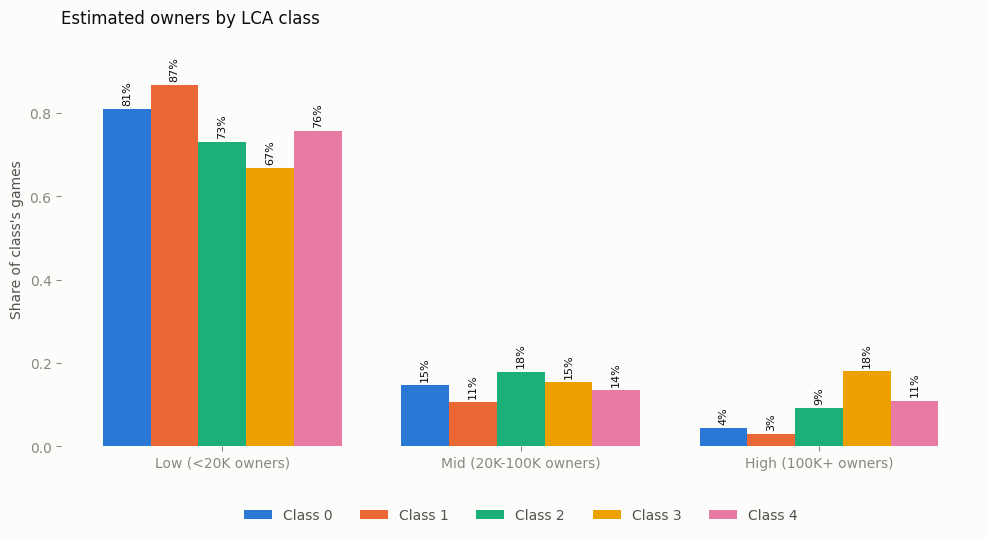

In [37]:
ct_lca = pd.crosstab(model_df['lca_class'], model_df['owner_group'], normalize='index')
ct_lca = ct_lca[group_order]
CLASS_COLORS = {
    0: '#2a78d6',  # blue
    1: '#eb6834',  # orange
    2: '#1baf7a',  # aqua
    3: '#eda100',  # yellow
    4: '#e87ba4',  # magenta
}

classes = sorted(ct_lca.index)
n_classes = len(classes)
bar_w = 0.8 / n_classes  # keep total cluster of bars under each x-tick at ~0.8 wide

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
x = np.arange(len(group_order))

for i, c in enumerate(classes):
    offset = (i - (n_classes - 1) / 2) * bar_w
    bars = ax.bar(x + offset, ct_lca.loc[c].values, width=bar_w,
                   color=CLASS_COLORS[c], label=f'Class {c}')
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in ct_lca.loc[c].values],
                 padding=3, fontsize=8, color=INK_PRIMARY, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(group_order, color=INK_PRIMARY)
ax.set_ylabel("Share of class's games", color=INK_SECONDARY)
ax.set_title('Estimated owners by LCA class', color=INK_PRIMARY, fontsize=12, loc='left')
ax.tick_params(colors=INK_MUTED)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(frameon=False, labelcolor=INK_SECONDARY, ncol=n_classes, loc='upper center',
          bbox_to_anchor=(0.5, -0.12))
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [23]:


# Drop the language-related indicators — the largest single block of likely-sparse,
# correlated binary tags, and the one we hypothesized was contributing most to
# LCA's preference for more classes.
LANG_CATEGORICAL = list(dict.fromkeys(
    ['lang_english'] + [c for c in CATEGORICAL_COLS if c.startswith('lang_')] + ['other_langs']
))
NUMERIC_COLS_REDUCED = [c for c in NUMERIC_COLS if c != 'total_langs']
CATEGORICAL_COLS_REDUCED = [c for c in CATEGORICAL_COLS if c not in LANG_CATEGORICAL]

print(f"Dropped 1 numeric and {len(CATEGORICAL_COLS) - len(CATEGORICAL_COLS_REDUCED)} categorical language features")

mixed_data_reduced, mixed_descriptor_reduced = get_mixed_descriptor(
    dataframe=model_df[NUMERIC_COLS_REDUCED + CATEGORICAL_COLS_REDUCED],
    continuous=NUMERIC_COLS_REDUCED,
    binary=CATEGORICAL_COLS_REDUCED,
)



Dropped 1 numeric and 11 categorical language features


In [58]:
lca_reduced_k5 = StepMix(n_components=5, measurement=mixed_descriptor_reduced,
                          n_init=20, random_state=RANDOM_STATE, verbose=0)
lca_reduced_k5.fit(mixed_data_reduced)
labels_reduced_k5 = lca_reduced_k5.predict(mixed_data_reduced)

ari = adjusted_rand_score(model_df['lca_class'], labels_reduced_k5)
print(f"ARI between full-feature and language-dropped k=5 class assignments: {ari:.3f}")

Fitting StepMix...


Initializations (n_init) : 100%|██████████| 20/20 [01:32<00:00,  4.64s/it, max_LL=-5.88e+4, max_avg_LL=-0.494]

ARI between full-feature and language-dropped k=5 class assignments: 0.549


In [100]:
#export model_df to parquet
model_df.to_parquet("clustered_steam_games.parquet", index=False)

In [59]:
model_df.columns

Index(['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu',
       'required_age', 'price', 'detailed_description', 'short_description',
       'supported_languages', 'full_audio_languages', 'reviews', 'windows',
       'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score',
       'positive', 'negative', 'score_rank', 'achievements', 'recommendations',
       'developers', 'publishers', 'categories', 'genres', 'tags',
       'release_year', 'release_month', 'age', 'has_metacritic_score',
       'owner_group', 'pub_prior_games_max', 'pub_prior_games_mean',
       'pub_all_first_release', 'pub_any_first_release', 'dev_prior_games_max',
       'dev_prior_games_mean', 'dev_all_first_release',
       'dev_any_first_release', 'lang_english', 'lang_chinese',
       'lang_japanese', 'lang_spanish', 'lang_german', 'lang_french',
       'lang_russian', 'lang_portuguese', 'lang_italian', 'lang_korean',
       'other_langs', 'total_langs', 'num_platforms', 'genre_action',
